# 04 · Comparación de agrupamientos
**Pregunta:** ¿cuántos grupos resumen los comportamientos de manera clara y estable?

Se comparan KMeans y Ward con 2 a 6 grupos. La elección utiliza solo RFM del periodo de observación.
Las compras posteriores quedan reservadas para el siguiente notebook.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, display

ROOT = Path.cwd()
while not (ROOT / "config/settings.yaml").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Abre el notebook dentro del repositorio.")
    ROOT = ROOT.parent
config = yaml.safe_load((ROOT / "config/settings.yaml").read_text(encoding="utf-8"))
REPORTS = ROOT / "reports"

In [2]:
from customer_segmentation.modeling import compare_models

rfm = pd.read_parquet(ROOT / "data/processed/customer_rfm.parquet")
model, comparison, selection = compare_models(rfm, config)
display(comparison.round(4))
display(selection)
assert comparison.selected.sum() == 1
published = pd.read_csv(REPORTS / "model_comparison.csv")
assert np.allclose(comparison.silhouette, published.silhouette, atol=1e-8)

,method,clusters,silhouette,davies_bouldin,calinski_harabasz,minimum_share,seed_ari,subsample_ari,inertia,selected
0,kmeans,2,0.4664,0.8607,4500.7019,0.3400,0.9991,0.9889,6379.0567,True
1,ward,2,0.4687,0.8438,4172.5984,0.2692,NaN,NaN,NaN,False
2,kmeans,3,0.3681,1.0284,3710.4826,0.1573,0.9865,0.9576,4793.5099,False
3,ward,3,0.3034,1.1496,3219.4951,0.2692,NaN,NaN,NaN,False
4,kmeans,4,0.3689,0.9781,3469.1491,0.1532,0.9805,0.9752,3821.6272,False
5,ward,4,0.2861,1.1860,2853.0034,0.0796,NaN,NaN,NaN,False
6,kmeans,5,0.3285,0.9952,3304.2010,0.0911,0.9851,0.9671,3209.2431,False
7,ward,5,0.3058,1.0670,2877.2649,0.0796,NaN,NaN,NaN,False
8,kmeans,6,0.3117,1.0022,3132.0332,0.0710,0.9861,0.9204,2816.4637,False
9,ward,6,0.3027,1.0288,2675.2943,0.0531,NaN,NaN,NaN,False


{'method': 'kmeans',
 'clusters': 2,
 'fallback': False,
 'rule': 'Mayor silhouette entre KMeans con tamaño y estabilidad mínimos; Ward se compara como referencia sin asignación nativa a nuevos clientes.',
 'silhouette': 0.4664158555899992,
 'subsample_ari': 0.9888823381599289}

## Regla de selección
Entre los KMeans con al menos 3 % de clientes por grupo y ARI medio de al menos 0,80 al ajustar
sobre submuestras, se elige el mayor silhouette. Se repiten tres semillas y tres submuestras
para comprobar sensibilidad. Ward es una referencia sin `predict` nativo para nuevos clientes.

Silhouette mide separación; ARI compara asignaciones. Ninguna métrica representa exactitud
contra segmentos verdaderos, porque no existe una etiqueta objetivo.

Grupos seleccionados: 2
Silhouette: 0.466
ARI por submuestreo: 0.989
Participación mínima: 34.0%


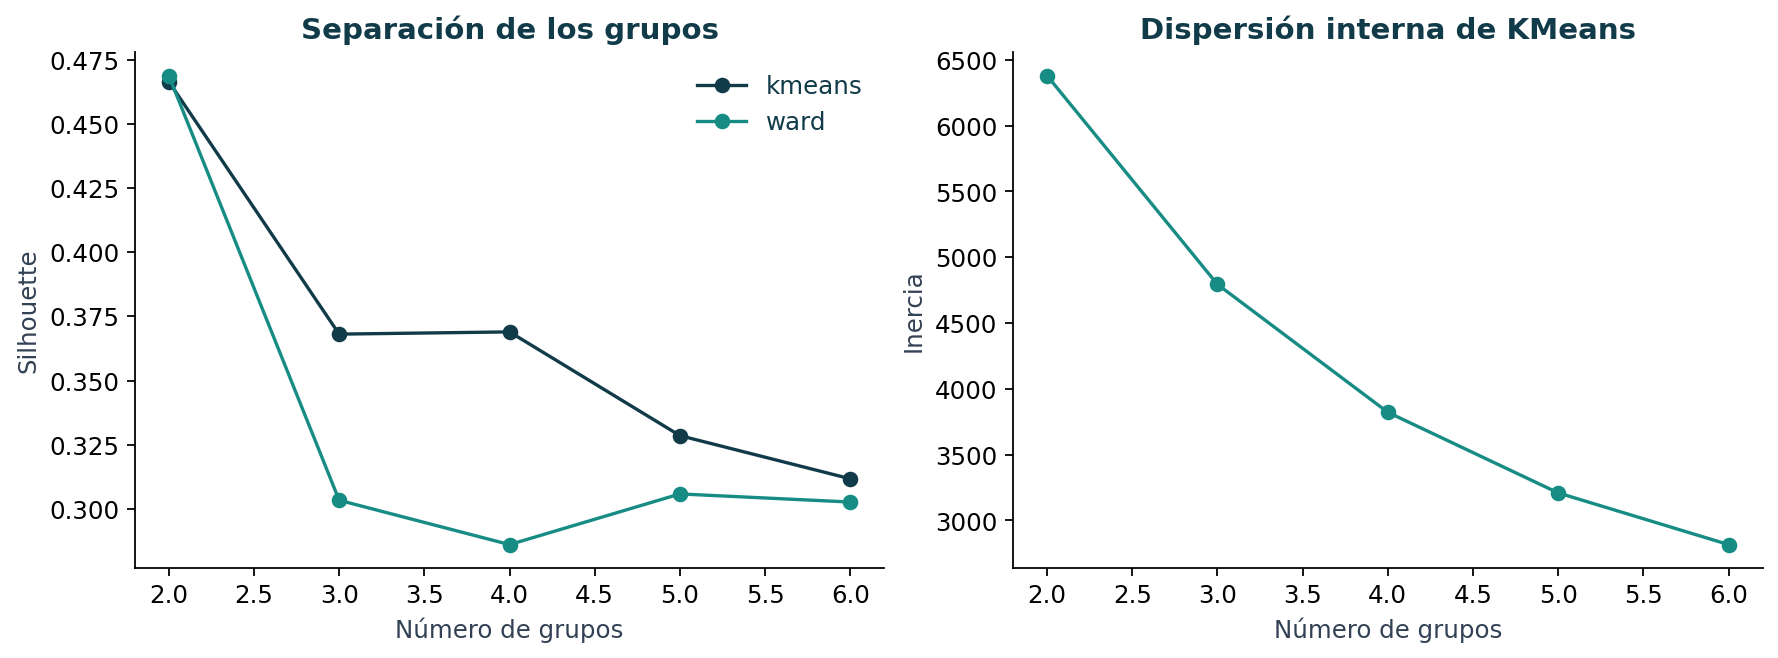

In [3]:
display(Image(filename=str(REPORTS / "figures/model_comparison.png")))
chosen = comparison.loc[comparison.selected].iloc[0]
print(f"Grupos seleccionados: {int(chosen.clusters)}")
print(f"Silhouette: {chosen.silhouette:.3f}")
print(f"ARI por submuestreo: {chosen.subsample_ari:.3f}")
print(f"Participación mínima: {chosen.minimum_share:.1%}")

## Interpretación
En la ejecución publicada se seleccionan dos grupos KMeans. Ward con dos grupos tiene un
silhouette ligeramente mayor; no se afirma que KMeans sea superior a todos los métodos.
Se elige dentro de una familia que permite asignar nuevos clientes con la misma transformación.

La diferencia entre dos perfiles amplios se presenta como resultado. No se fuerza una lista
predefinida de clientes VIP, nuevos o perdidos. La estabilidad por submuestreo no demuestra
estabilidad entre periodos distintos.

[Continuar: perfiles y acciones](05_segment_profiles.ipynb)